# Экзаменационная задача №3. Выбор ценовой стратегии для AI-сервиса по созданию контента

- **Курс:** Экономика информатизации, лекция №4 «Ценовые стратегии в цифровой среде»
- **Студент:** Солдатов Сергей Юрьевич
- **Группа:** ПИ4-1
- **Дата:** 2026-11-19

In [1]:
# ============================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №03: ВЫБОР ЦЕНОВОЙ СТРАТЕГИИ ДЛЯ AI-СЕРВИСА
#                             ПО СОЗДАНИЮ КОНТЕНТА
# ============================================================================
# Дата: 2026-11-19
# Студент: Солдатов Сергей Юрьевич
# Группа: ПИ4-1
# ============================================================================

# Библиотеки: pandas — таблицы, matplotlib — графики
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MLN = 1_000_000  # рублей в миллионе


def fmt(value, digits=0):
    """Число в привычной записи: 7 950 или 50,07."""
    value = round(value, digits) + 0          # «+ 0» убирает минус у нуля
    text = f"{value:,.{digits}f}"
    return text.replace(",", " ").replace(".", ",").replace("-", "−")


def pct(value, digits=0):
    """Доля в процентах: 0.05 -> 5%."""
    return fmt(value * 100, digits) + "%"


def signed(value, digits=0):
    """Число со знаком: +30 или −30."""
    return ("+" if value > 0 else "") + fmt(value, digits)


def lower_first(text):
    """Первая буква — строчная: «Реклама» -> «реклама»."""
    return text[0].lower() + text[1:]


# Единый вид графиков: светлый фон, сетка, без верхней и правой рамки
plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

# Цвета на графиках: по одному на каждую стратегию и серый для порогов
BLUE, ORANGE, GREEN, PURPLE, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#7c5cc4", "#52514e"

# Графики сохраняем в reports/figures (ноутбук запускается из папки notebooks)
FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

## Экономическая постановка задачи

**Проблема.** Стартап «AI-Копирайтер» разработал сервис, который с помощью AI генерирует тексты для маркетинга, SEO
и социальных сетей. Перед выходом на рынок нужно выбрать, как брать деньги с пользователей. Вариантов четыре:
Freemium, подписка, динамическое и персонализированное ценообразование.

**Актуальность.** У цифрового продукта предельные затраты близки к нулю, поэтому цену нельзя вывести из
себестоимости. Ее выбирают по ценности для пользователя и по метрикам: сколько пользователей платит, как долго
они остаются и сколько стоит их привлечь.

**Цель.** Выбрать ценовую стратегию для вывода сервиса на рынок и обосновать выбор расчетами.

**Задачи:**
1. посчитать ARPU, LTV и отношение LTV/CAC для каждой стратегии и канала привлечения;
2. спрогнозировать прибыль за 3 года и посчитать NPV;
3. проверить чувствительность к конверсии, оттоку (Churn) и CAC;
4. выбрать стратегию, составить план внедрения и оценить риски.

## 1. Исходные данные

### 1.1. Параметры проекта

Все значения взяты из условия задачи (методичка, лекция №4, раздел «Экзаменационная задача»).

In [2]:
# Все исходные данные лежат в одном словаре: меняем значение здесь — пересчитывается всё
BASE = {
    "market": 500_000,               # потенциальный рынок в России, пользователей
    "market_growth": 0.25,           # темп роста рынка в год
    "competitor_prices": (500, 5_000),   # цены конкурентов, руб./мес.
    "development": 15_000_000,       # затраты на разработку, руб.
    "support": 2_000_000,            # поддержание и облачные услуги, руб./мес.
    # CAC — затраты на привлечение одного пользователя по каналам, руб.
    "cac": {
        "Реклама": 1_500,
        "Контент-маркетинг и SEO": 800,
        "Виральный рост": 100,
    },
    # Стратегии: цена от и до (руб./мес.), конверсия в платных, Churn (отток в месяц)
    "strategies": {
        "Freemium": {"price": (2_000, 2_000), "conversion": 0.02, "churn": 0.08},
        "Подписка": {"price": (1_500, 1_500), "conversion": 0.20, "churn": 0.05},
        "Динамическая": {"price": (500, 2_000), "conversion": 0.15, "churn": 0.06},
        "Персонализированная": {"price": (300, 5_000), "conversion": 0.12, "churn": 0.04},
    },
    "start_users": 1_000,            # база пользователей в году 0
    "growth": (1.00, 0.50, 0.20),    # прирост базы в годах 1, 2 и 3
    "rate": 0.12,                    # ставка дисконтирования, годовых
    "shift": 0.30,                   # изменение параметра в анализе чувствительности
}
STRATEGIES = BASE["strategies"]      # короткое имя для словаря стратегий
YEARS = len(BASE["growth"])          # горизонт планирования, лет

# Таблица стратегий строится из словаря, поэтому всегда совпадает с расчетом
rows = {}
for name, s in STRATEGIES.items():
    low, high = s["price"]
    rows[name] = {
        "Цена, руб./мес.": fmt(low) if low == high else f"{fmt(low)}–{fmt(high)}",
        "Конверсия (платные)": pct(s["conversion"]),
        "Churn": pct(s["churn"]),
    }
display(pd.DataFrame(rows).T)

# Остальные параметры
low, high = BASE["competitor_prices"]
source_table = pd.DataFrame(
    [
        ("Потенциальный рынок, пользователей", fmt(BASE["market"])),
        ("Темп роста рынка в год", pct(BASE["market_growth"])),
        ("Цены конкурентов, руб./мес.", f"{fmt(low)}–{fmt(high)}"),
        ("Затраты на разработку, руб.", fmt(BASE["development"])),
        ("Поддержание и облачные услуги, руб./мес.", fmt(BASE["support"])),
        *[(f"CAC, {lower_first(channel)}, руб.", fmt(cac))
          for channel, cac in BASE["cac"].items()],
        ("База пользователей в году 0", fmt(BASE["start_users"])),
        ("Прирост базы по годам", " / ".join(pct(g) for g in BASE["growth"])),
        ("Ставка дисконтирования, годовых", pct(BASE["rate"])),
        ("Горизонт планирования, лет", fmt(YEARS)),
        ("Изменение параметров в анализе чувствительности", "±" + pct(BASE["shift"])),
    ],
    columns=["Параметр", "Значение"],
)
display(source_table)

,"Цена, руб./мес.",Конверсия (платные),Churn
Freemium,2 000,2%,8%
Подписка,1 500,20%,5%
Динамическая,500–2 000,15%,6%
Персонализированная,300–5 000,12%,4%


,Параметр,Значение
0,"Потенциальный рынок, пользователей",500 000
1,Темп роста рынка в год,25%
2,"Цены конкурентов, руб./мес.",500–5 000
3,"Затраты на разработку, руб.",15 000 000
4,"Поддержание и облачные услуги, руб./мес.",2 000 000
5,"CAC, реклама, руб.",1 500
6,"CAC, контент-маркетинг и SEO, руб.",800
7,"CAC, виральный рост, руб.",100
8,База пользователей в году 0,1 000
9,Прирост базы по годам,100% / 50% / 20%


### 1.2. Справочные данные

Справочные данные вводятся там, где они нужны: формулы из условия и лекции №4 — в разделе 2.1, порог LTV/CAC —
в разделе 2.3, матрица выбора стратегии и целевые значения метрик из лекции — в разделе 2.6.

### 1.3. Дополнительные условия (допущения)

В условии есть места, которые можно понять по-разному. Каждое такое место разобрано перед тем расчетом, на который
оно влияет: допущения Д1–Д3 — в разделе 2.3, Д4–Д8 — в разделе 2.4, Д9 — в разделе 2.5.

## 2. Расчеты

### 2.1. Математическая модель

**ARPU** — средний доход с одного пользователя в месяц:

$$ARPU = P \cdot r$$

где $P$ — цена, $r$ — конверсия в платных пользователей.

**LTV** — доход с одного пользователя за весь срок его жизни в сервисе:

$$LTV = \frac{ARPU}{Churn} = ARPU \cdot T, \qquad T = \frac{1}{Churn}$$

**Эффективность канала привлечения:** $LTV / CAC$. По лекции бизнес устойчив при $LTV / CAC \ge 3$.

**База пользователей:** $N_t = N_{t-1} \cdot (1 + g_t)$, где $g_t$ — прирост года $t$ (100%, 50%, 20%).

**Прибыль года:**

$$П_t = ARPU \cdot N_t \cdot 12 - CAC \cdot (N_t - N_{t-1}) - C_{поддержание} \cdot 12$$

**NPV:** $NPV = -I_0 + \sum_{t=1}^{3} \dfrac{П_t}{(1+r)^t}$, где $I_0$ — затраты на разработку, $r$ = 12% годовых.

**Откуда формулы.** ARPU = Цена × Конверсия — критерии оценки задачи и лекция №4, раздел 2.2. LTV = ARPU / Churn
и срок жизни 1 / Churn — условие и раздел 3.2. Порог LTV / CAC ≥ 3 — раздел 3.2. Прибыль и NPV — формула NPV
подписки из раздела 3.4.

**Почему эти методы.** ARPU, LTV и LTV/CAC — основные метрики ценовых стратегий из лекции №4: они показывают,
сколько приносит пользователь и окупается ли его привлечение. NPV нужен, чтобы сравнить стратегии по деньгам
за 3 года с учетом стоимости денег во времени.

### 2.2. Функции расчета

Шесть коротких функций. Каждая считает один показатель из раздела 2.1.

In [3]:
def price_of(strategy):
    """Цена стратегии; для диапазона цен — середина диапазона."""
    low, high = strategy["price"]
    return (low + high) / 2


def arpu_of(strategy):
    """ARPU: цена × конверсия, руб. в месяц на одного пользователя."""
    return price_of(strategy) * strategy["conversion"]


def ltv_of(strategy):
    """LTV: ARPU / Churn, руб. за весь срок жизни пользователя."""
    return arpu_of(strategy) / strategy["churn"]


def users_by_year():
    """База пользователей по годам, начиная с года 0."""
    users = [BASE["start_users"]]
    for growth in BASE["growth"]:
        users.append(users[-1] * (1 + growth))
    return users


def forecast(strategy, cac):
    """Таблица по годам: доход, затраты, прибыль и дисконтированная прибыль."""
    users = users_by_year()
    # Год 0: дохода еще нет, есть только затраты на разработку
    rows = [{"Год": 0, "Пользователи": users[0], "Новые": 0.0, "Доход": 0.0,
             "Привлечение": 0.0, "Поддержание": 0.0, "Разработка": BASE["development"]}]
    for year in range(1, len(users)):
        new_users = users[year] - users[year - 1]           # прирост базы за год
        rows.append({"Год": year, "Пользователи": users[year], "Новые": new_users,
                     "Доход": arpu_of(strategy) * users[year] * 12,
                     "Привлечение": cac * new_users,
                     "Поддержание": BASE["support"] * 12, "Разработка": 0.0})
    table = pd.DataFrame(rows).set_index("Год")
    table["Прибыль"] = (table["Доход"] - table["Привлечение"]
                        - table["Поддержание"] - table["Разработка"])
    table["Дисконт"] = 1 / (1 + BASE["rate"]) ** table.index    # коэффициент года
    table["Дисконтированная прибыль"] = table["Прибыль"] * table["Дисконт"]
    return table


def npv(table):
    """NPV: сумма дисконтированной прибыли по годам."""
    return table["Дисконтированная прибыль"].sum()

### 2.3. Часть 1. ARPU, LTV и LTV/CAC (задания 1–3)

Для этих расчетов нужны три допущения.

| № | Допущение | Почему так |
|---|---|---|
| Д1 | Для стратегий с диапазоном цен берется середина диапазона: 1 250 руб. для динамической и 2 650 руб. для персонализированной | В условии задан только диапазон. Как цены распределены внутри него, не сказано |
| Д2 | ARPU = Цена × Конверсия и считается на одного пользователя базы, включая тех, кто не платит | Так записано в критериях оценки и в лекции (раздел 2.2) |
| Д3 | Churn — отток за месяц | Цены и ARPU заданы за месяц; в лекции (раздел 3.2) Churn — месячный отток. Тогда LTV = ARPU / Churn получается в рублях |

In [4]:
# Задания 1–2. ARPU, срок жизни клиента и LTV для каждой стратегии
rows = {}
for name, s in STRATEGIES.items():
    rows[name] = {
        "Цена в расчете, руб./мес.": fmt(price_of(s)),
        "Конверсия": pct(s["conversion"]),
        "ARPU, руб./мес.": fmt(arpu_of(s), 1),
        "Churn": pct(s["churn"]),
        "Срок жизни, мес.": fmt(1 / s["churn"], 1),
        "LTV, руб.": fmt(ltv_of(s)),
    }
metrics_table = pd.DataFrame(rows).T
display(metrics_table)

,"Цена в расчете, руб./мес.",Конверсия,"ARPU, руб./мес.",Churn,"Срок жизни, мес.","LTV, руб."
Freemium,2 000,2%,"40,0",8%,"12,5",500
Подписка,1 500,20%,"300,0",5%,"20,0",6 000
Динамическая,1 250,15%,"187,5",6%,"16,7",3 125
Персонализированная,2 650,12%,"318,0",4%,"25,0",7 950


In [5]:
# Задание 3. LTV/CAC для каждой стратегии и каждого канала привлечения
TARGET_LTV_CAC = 3          # условие устойчивости из лекции №4 (раздел 3.2): LTV / CAC ≥ 3
CAC_AVG = sum(BASE["cac"].values()) / len(BASE["cac"])     # средний CAC по трем каналам
channels = {**BASE["cac"], "Средний CAC": CAC_AVG}

ratio = pd.DataFrame({
    f"{channel} ({fmt(cac)} руб.)": {name: ltv_of(s) / cac for name, s in STRATEGIES.items()}
    for channel, cac in channels.items()
})
display(ratio.apply(lambda column: column.map(lambda value: fmt(value, 2))))

# Какие пары «стратегия — канал» проходят порог устойчивости из лекции
print(f"Порог из лекции: LTV / CAC ≥ {TARGET_LTV_CAC}. Его проходят каналы:")
for name, s in STRATEGIES.items():
    good = [lower_first(channel) for channel, cac in BASE["cac"].items()
            if ltv_of(s) / cac >= TARGET_LTV_CAC]
    print(f"  {name}: {', '.join(good) if good else 'ни один'}")

,Реклама (1 500 руб.),Контент-маркетинг и SEO (800 руб.),Виральный рост (100 руб.),Средний CAC (800 руб.)
Freemium,"0,33","0,62","5,00","0,62"
Подписка,"4,00","7,50","60,00","7,50"
Динамическая,"2,08","3,91","31,25","3,91"
Персонализированная,"5,30","9,94","79,50","9,94"


Порог из лекции: LTV / CAC ≥ 3. Его проходят каналы:
  Freemium: виральный рост
  Подписка: реклама, контент-маркетинг и SEO, виральный рост
  Динамическая: контент-маркетинг и SEO, виральный рост
  Персонализированная: реклама, контент-маркетинг и SEO, виральный рост


### 2.4. Часть 2. Прибыль за 3 года и NPV (задания 4–5)

Для прибыли и NPV нужны пять допущений.

| № | Допущение | Почему так |
|---|---|---|
| Д4 | Число пользователей по годам задано моделью роста из условия: 1 000 → 2 000 → 3 000 → 3 600. Оно одинаково для всех стратегий | Так записано в задании 4. Отток влияет на LTV, а в прибыль отдельно не входит: модель роста уже дает итоговую базу |
| Д5 | Прибыль года = доход − затраты на привлечение − затраты на поддержание. Доход года = ARPU × база года × 12 | Формула NPV подписки из лекции (раздел 3.4). База года — число пользователей после прироста этого года |
| Д6 | В прибыли и NPV используется средний CAC по трем каналам: 800 руб. Привлечение первых 1 000 пользователей уже оплачено | Доли каналов в условии не заданы, считаем их равными. По каждому каналу отдельно посчитано LTV/CAC (задание 3) |
| Д7 | Затраты на разработку (15 млн руб.) относятся на год 0. Потоки годов 1–3 относятся на конец года | Стандартное упрощение при расчете NPV |
| Д8 | Размер рынка, темп его роста и цены конкурентов в формулы не входят | Модель роста в задании 4 задана от базы пользователей, а не от рынка. Эти данные используются в анализе |

In [6]:
# Задание 4. База пользователей и затраты по годам — они одинаковы для всех стратегий
common = forecast(STRATEGIES["Подписка"], CAC_AVG)
costs_view = common[["Пользователи", "Новые", "Привлечение", "Поддержание", "Разработка"]].copy()
money = ["Привлечение", "Поддержание", "Разработка"]
costs_view[money] = costs_view[money] / MLN
costs_view.columns = ["Пользователи", "Новые"] + [f"{name}, млн руб." for name in money]
display(costs_view.apply(lambda column: column.map(
    lambda value: fmt(value, 2) if "млн" in column.name else fmt(value))))
print(f"К концу {YEARS}-го года база — {fmt(common['Пользователи'].iloc[-1])} пользователей, "
      f"это {pct(common['Пользователи'].iloc[-1] / BASE['market'], 2)} рынка")

,Пользователи,Новые,"Привлечение, млн руб.","Поддержание, млн руб.","Разработка, млн руб."
Год,,,,,
0,1 000,0,"0,00","0,00","15,00"
1,2 000,1 000,"0,80","24,00","0,00"
2,3 000,1 000,"0,80","24,00","0,00"
3,3 600,600,"0,48","24,00","0,00"


К концу 3-го года база — 3 600 пользователей, это 0,72% рынка


In [7]:
# Задание 4. Доход и прибыль по годам для каждой стратегии, млн руб.
runs = {name: forecast(s, CAC_AVG) for name, s in STRATEGIES.items()}   # расчет по стратегиям

revenue = pd.DataFrame({name: run["Доход"] / MLN for name, run in runs.items()}).T
revenue.columns = [f"Год {year}" for year in revenue.columns]
revenue[f"Итого за {YEARS} года"] = revenue.sum(axis=1)
print("Доход, млн руб.")
display(revenue.drop(columns="Год 0").apply(lambda column: column.map(lambda v: fmt(v, 2))))

profit = pd.DataFrame({name: run["Прибыль"] / MLN for name, run in runs.items()}).T
profit.columns = [f"Год {year}" for year in profit.columns]
profit[f"Итого за {YEARS} года"] = profit.sum(axis=1)
print("Прибыль (убыток), млн руб. Год 0 — затраты на разработку")
display(profit.apply(lambda column: column.map(lambda v: fmt(v, 2))))

Доход, млн руб.


,Год 1,Год 2,Год 3,Итого за 3 года
Freemium,"0,96","1,44","1,73","4,13"
Подписка,"7,20","10,80","12,96","30,96"
Динамическая,"4,50","6,75","8,10","19,35"
Персонализированная,"7,63","11,45","13,74","32,82"


Прибыль (убыток), млн руб. Год 0 — затраты на разработку


,Год 0,Год 1,Год 2,Год 3,Итого за 3 года
Freemium,"−15,00","−23,84","−23,36","−22,75","−84,95"
Подписка,"−15,00","−17,60","−14,00","−11,52","−58,12"
Динамическая,"−15,00","−20,30","−18,05","−16,38","−69,73"
Персонализированная,"−15,00","−17,17","−13,35","−10,74","−56,26"


In [8]:
# Задание 5. NPV: прибыль каждого года умножаем на коэффициент дисконтирования
print("Коэффициенты дисконтирования при ставке " + pct(BASE["rate"]) + ": "
      + "; ".join(f"год {year} — {fmt(k, 4)}" for year, k in common["Дисконт"].items()))

discounted = pd.DataFrame(
    {name: run["Дисконтированная прибыль"] / MLN for name, run in runs.items()}).T
discounted.columns = [f"Год {year}" for year in discounted.columns]
npv_by_strategy = {name: npv(run) for name, run in runs.items()}     # NPV в рублях
discounted["NPV, млн руб."] = [value / MLN for value in npv_by_strategy.values()]
print("Дисконтированная прибыль по годам и NPV, млн руб.")
display(discounted.apply(lambda column: column.map(lambda v: fmt(v, 2))))

best_npv = max(npv_by_strategy, key=npv_by_strategy.get)
print(f"Наибольший NPV — у стратегии «{best_npv}»: "
      f"{fmt(npv_by_strategy[best_npv] / MLN, 2)} млн руб.")

Коэффициенты дисконтирования при ставке 12%: год 0 — 1,0000; год 1 — 0,8929; год 2 — 0,7972; год 3 — 0,7118
Дисконтированная прибыль по годам и NPV, млн руб.


,Год 0,Год 1,Год 2,Год 3,"NPV, млн руб."
Freemium,"−15,00","−21,29","−18,62","−16,19","−71,10"
Подписка,"−15,00","−15,71","−11,16","−8,20","−50,07"
Динамическая,"−15,00","−18,12","−14,39","−11,66","−59,17"
Персонализированная,"−15,00","−15,33","−10,64","−7,65","−48,62"


Наибольший NPV — у стратегии «Персонализированная»: −48,62 млн руб.


### 2.5. Часть 3. Анализ чувствительности (задания 6–7)

Меняем по одному параметру на ±30% и смотрим, как меняются LTV/CAC и NPV.

| № | Допущение | Почему так |
|---|---|---|
| Д9 | В анализе чувствительности параметры меняются по одному, остальные остаются базовыми. Показатели: LTV/CAC при среднем CAC и NPV | В задании 6 параметры перечислены по отдельности |

In [9]:
def variant(strategy, cac, parameter, factor):
    """LTV/CAC и NPV стратегии, если один параметр умножить на factor."""
    changed = dict(strategy)
    if parameter == "cac":
        cac = cac * factor
    else:
        changed[parameter] = strategy[parameter] * factor
    return ltv_of(changed) / cac, npv(forecast(changed, cac))


# Список вариантов: базовый и по два изменения каждого параметра
shift = BASE["shift"]
cases = [("Базовый вариант", "cac", 1)]
for parameter, title in (("conversion", "Конверсия"), ("churn", "Churn"), ("cac", "CAC")):
    for factor in (1 - shift, 1 + shift):
        cases.append((f"{title} {signed((factor - 1) * 100)}%", parameter, factor))

# Задание 6. Считаем каждый вариант для каждой стратегии
ratio_rows, npv_rows = {}, {}
for label, parameter, factor in cases:
    results = {name: variant(s, CAC_AVG, parameter, factor) for name, s in STRATEGIES.items()}
    ratio_rows[label] = {name: result[0] for name, result in results.items()}
    npv_rows[label] = {name: result[1] / MLN for name, result in results.items()}
sens_ratio = pd.DataFrame(ratio_rows).T          # LTV/CAC по вариантам
sens_npv = pd.DataFrame(npv_rows).T              # NPV по вариантам, млн руб.

print(f"LTV/CAC при среднем CAC {fmt(CAC_AVG)} руб.")
display(sens_ratio.apply(lambda column: column.map(lambda v: fmt(v, 2))))
print("NPV, млн руб.")
display(sens_npv.apply(lambda column: column.map(lambda v: fmt(v, 2))))

LTV/CAC при среднем CAC 800 руб.


,Freemium,Подписка,Динамическая,Персонализированная
Базовый вариант,"0,62","7,50","3,91","9,94"
Конверсия −30%,"0,44","5,25","2,73","6,96"
Конверсия +30%,"0,81","9,75","5,08","12,92"
Churn −30%,"0,89","10,71","5,58","14,20"
Churn +30%,"0,48","5,77","3,00","7,64"
CAC −30%,"0,89","10,71","5,58","14,20"
CAC +30%,"0,48","5,77","3,00","7,64"


NPV, млн руб.


,Freemium,Подписка,Динамическая,Персонализированная
Базовый вариант,"−71,10","−50,07","−59,17","−48,62"
Конверсия −30%,"−72,07","−57,35","−63,72","−56,33"
Конверсия +30%,"−70,13","−42,80","−54,62","−40,90"
Churn −30%,"−71,10","−50,07","−59,17","−48,62"
Churn +30%,"−71,10","−50,07","−59,17","−48,62"
CAC −30%,"−70,59","−49,57","−58,67","−48,11"
CAC +30%,"−71,61","−50,58","−59,68","−49,13"


In [10]:
# Задание 7. Устойчивость: что происходит с показателями в худшем и лучшем варианте
rows = {}
for name in STRATEGIES:
    worst, best = sens_ratio[name].min(), sens_ratio[name].max()
    rows[name] = {
        "LTV/CAC базовый": fmt(sens_ratio[name].iloc[0], 2),
        "LTV/CAC худший": fmt(worst, 2),
        "LTV/CAC лучший": fmt(best, 2),
        f"Порог {TARGET_LTV_CAC} выдержан всегда": "да" if worst >= TARGET_LTV_CAC else "нет",
        "NPV худший, млн руб.": fmt(sens_npv[name].min(), 2),
        "NPV лучший, млн руб.": fmt(sens_npv[name].max(), 2),
        "NPV бывает положительным": "да" if sens_npv[name].max() > 0 else "нет",
    }
robust_table = pd.DataFrame(rows).T
display(robust_table)

# Самая устойчивая стратегия — с наибольшим запасом до порога в худшем варианте
most_robust = sens_ratio.min().idxmax()
print(f"Наибольший запас до порога — у стратегии «{most_robust}»: "
      f"худший LTV/CAC = {fmt(sens_ratio[most_robust].min(), 2)}")

,LTV/CAC базовый,LTV/CAC худший,LTV/CAC лучший,Порог 3 выдержан всегда,"NPV худший, млн руб.","NPV лучший, млн руб.",NPV бывает положительным
Freemium,"0,62","0,44","0,89",нет,"−72,07","−70,13",нет
Подписка,"7,50","5,25","10,71",да,"−57,35","−42,80",нет
Динамическая,"3,91","2,73","5,58",нет,"−63,72","−54,62",нет
Персонализированная,"9,94","6,96","14,20",да,"−56,33","−40,90",нет


Наибольший запас до порога — у стратегии «Персонализированная»: худший LTV/CAC = 6,96


### 2.6. Часть 4. Данные для выбора стратегии и метрики (задания 8–9)

Сводим в одну таблицу результаты расчетов и качественные оценки стратегий из лекции (раздел 7.1).

In [11]:
# Матрица выбора стратегии из лекции №4 (раздел 7.1): качественные оценки
LECTURE_MATRIX = pd.DataFrame(
    {
        "Freemium": ("Средняя", "Высокие", "Низкий", "Массовых продуктов"),
        "Подписка": ("Низкая", "Низкие", "Низкий", "B2B, сервисы"),
        "Динамическая": ("Высокая", "Высокие", "Средний", "Транспорт, отели"),
        "Персонализированная": ("Очень высокая", "Очень высокие", "Высокий", "E-commerce"),
    },
    index=["Сложность внедрения", "Затраты на внедрение", "Риск пользователей", "Подходит для"],
).T
display(LECTURE_MATRIX)

,Сложность внедрения,Затраты на внедрение,Риск пользователей,Подходит для
Freemium,Средняя,Высокие,Низкий,Массовых продуктов
Подписка,Низкая,Низкие,Низкий,"B2B, сервисы"
Динамическая,Высокая,Высокие,Средний,"Транспорт, отели"
Персонализированная,Очень высокая,Очень высокие,Высокий,E-commerce


In [12]:
# Задание 8. Сводная таблица: расчеты и оценки из лекции
summary_table = pd.DataFrame({
    name: {
        "ARPU, руб./мес.": fmt(arpu_of(s), 1),
        "LTV, руб.": fmt(ltv_of(s)),
        "LTV/CAC худший": fmt(sens_ratio[name].min(), 2),
        "NPV, млн руб.": fmt(npv_by_strategy[name] / MLN, 2),
    }
    for name, s in STRATEGIES.items()
}).T.join(LECTURE_MATRIX)
display(summary_table)

# Выбранная стратегия; обоснование — в разделе 4.2
CHOICE = "Подписка"
gap = npv_by_strategy[best_npv] - npv_by_strategy[CHOICE]
print(f"Лучший NPV у стратегии «{best_npv}». Отставание стратегии «{CHOICE}»: "
      f"{fmt(gap / MLN, 2)} млн руб., это {pct(gap / abs(npv_by_strategy[CHOICE]), 1)} ее NPV")

# Проверка допущения Д1: при какой средней цене стратегия с диапазоном цен
# дает такой же ARPU, как выбранная
for name, s in STRATEGIES.items():
    low, high = s["price"]
    if low != high:
        equal_price = arpu_of(STRATEGIES[CHOICE]) / s["conversion"]
        print(f"{name}: тот же ARPU, что у стратегии «{CHOICE}», при средней цене "
              f"{fmt(equal_price)} руб. (диапазон {fmt(low)}–{fmt(high)}, в расчете "
              f"{fmt(price_of(s))})")

,"ARPU, руб./мес.","LTV, руб.",LTV/CAC худший,"NPV, млн руб.",Сложность внедрения,Затраты на внедрение,Риск пользователей,Подходит для
Freemium,"40,0",500,"0,44","−71,10",Средняя,Высокие,Низкий,Массовых продуктов
Подписка,"300,0",6 000,"5,25","−50,07",Низкая,Низкие,Низкий,"B2B, сервисы"
Динамическая,"187,5",3 125,"2,73","−59,17",Высокая,Высокие,Средний,"Транспорт, отели"
Персонализированная,"318,0",7 950,"6,96","−48,62",Очень высокая,Очень высокие,Высокий,E-commerce


Лучший NPV у стратегии «Персонализированная». Отставание стратегии «Подписка»: 1,46 млн руб., это 2,9% ее NPV
Динамическая: тот же ARPU, что у стратегии «Подписка», при средней цене 2 000 руб. (диапазон 500–2 000, в расчете 1 250)
Персонализированная: тот же ARPU, что у стратегии «Подписка», при средней цене 2 500 руб. (диапазон 300–5 000, в расчете 2 650)


In [13]:
# Целевые значения метрик из лекции №4 (раздел 3.4)
TARGET_CHURN = 0.05         # Churn для B2B: ниже 5% в месяц
TARGET_PAYBACK = 12         # окупаемость CAC: быстрее 12 месяцев

# Задание 9. Ключевые метрики выбранной стратегии: значение по расчету и цель из лекции
chosen = STRATEGIES[CHOICE]
users = users_by_year()
mrr = [arpu_of(chosen) * n / MLN for n in users[1:]]              # MRR по годам, млн руб.
ratios = [ltv_of(chosen) / cac for cac in BASE["cac"].values()]   # LTV/CAC по каналам
# Окупаемость CAC = CAC / ARPU (себестоимость на пользователя в условии не задана)
paybacks = [cac / arpu_of(chosen) for cac in BASE["cac"].values()]

kpi_table = pd.DataFrame(
    [
        ("MRR по годам, млн руб.", " → ".join(fmt(value, 2) for value in mrr),
         f"не ниже {fmt(BASE['support'] / MLN, 2)} (затраты на поддержание в месяц)"),
        ("Churn в месяц", pct(chosen["churn"]), f"ниже {pct(TARGET_CHURN)}"),
        ("LTV/CAC по каналам", " / ".join(fmt(value, 1) for value in ratios),
         f"не ниже {TARGET_LTV_CAC}"),
        ("Окупаемость CAC по каналам, мес.", " / ".join(fmt(value, 1) for value in paybacks),
         f"быстрее {TARGET_PAYBACK}"),
    ],
    columns=["Метрика", "По расчету", "Цель"],
)
display(kpi_table)

# Ориентир для дорожной карты: при какой базе MRR покрывает поддержание
users_needed = BASE["support"] / arpu_of(chosen)
print(f"MRR покрывает затраты на поддержание при базе {fmt(users_needed)} пользователей "
      f"({pct(users_needed / BASE['market'], 1)} рынка); в году {YEARS} база — {fmt(users[-1])}")

,Метрика,По расчету,Цель
0,"MRR по годам, млн руб.","0,60 → 0,90 → 1,08","не ниже 2,00 (затраты на поддержание в месяц)"
1,Churn в месяц,5%,ниже 5%
2,LTV/CAC по каналам,"4,0 / 7,5 / 60,0",не ниже 3
3,"Окупаемость CAC по каналам, мес.","5,0 / 2,7 / 0,3",быстрее 12


MRR покрывает затраты на поддержание при базе 6 667 пользователей (1,3% рынка); в году 3 база — 3 600


### 2.7. Визуализация результатов

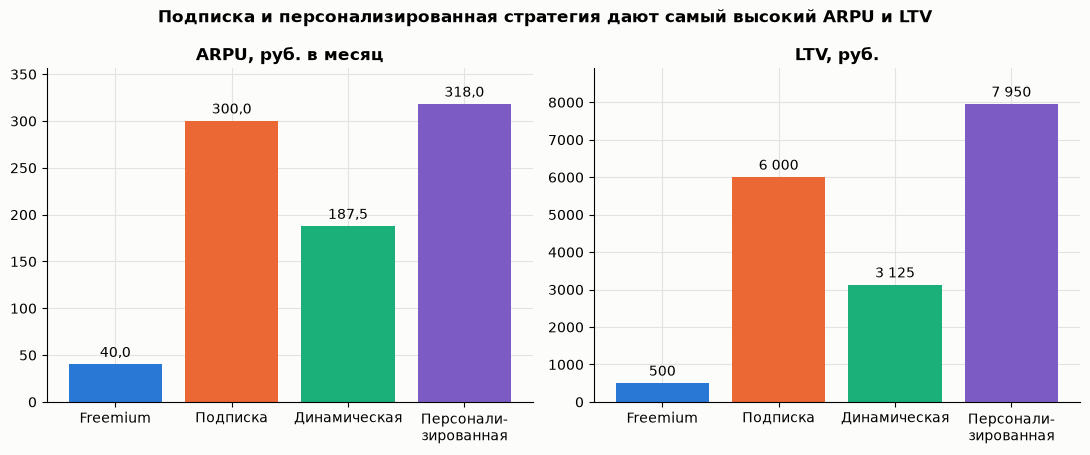

In [14]:
# Цвет каждой стратегии — один и тот же на всех графиках
COLORS = dict(zip(STRATEGIES, (BLUE, ORANGE, GREEN, PURPLE)))
names = list(STRATEGIES)
# Длинные названия переносим на вторую строку, чтобы подписи не налезали друг на друга
short = [name if len(name) <= 12 else name[:9] + "-\n" + name[9:] for name in names]

# График 1. ARPU и LTV по стратегиям
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, values, digits, title in (
    (left, [arpu_of(s) for s in STRATEGIES.values()], 1, "ARPU, руб. в месяц"),
    (right, [ltv_of(s) for s in STRATEGIES.values()], 0, "LTV, руб."),
):
    bars = ax.bar(short, values, color=[COLORS[name] for name in names])
    ax.bar_label(bars, labels=[fmt(value, digits) for value in values], padding=3)
    ax.set_title(title)
    ax.margins(y=0.12)
fig.suptitle("Подписка и персонализированная стратегия дают самый высокий ARPU и LTV",
             fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "03_arpu_ltv.png"), dpi=160, bbox_inches="tight")
plt.show()

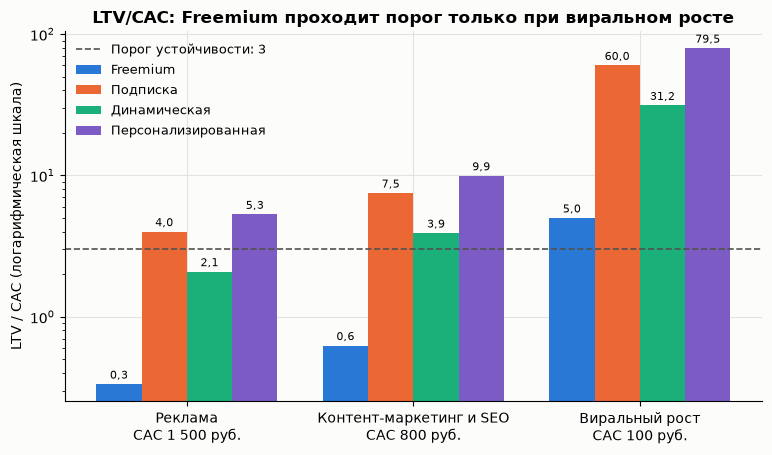

In [15]:
# График 2. LTV/CAC по каналам привлечения (логарифмическая шкала) и порог из лекции
channel_names = list(BASE["cac"])
x = np.arange(len(channel_names))
width = 0.2
fig, ax = plt.subplots()
for index, name in enumerate(names):
    values = [ltv_of(STRATEGIES[name]) / cac for cac in BASE["cac"].values()]
    bars = ax.bar(x + (index - 1.5) * width, values, width, color=COLORS[name], label=name)
    ax.bar_label(bars, labels=[fmt(value, 1) for value in values], padding=2, fontsize=8)
ax.axhline(TARGET_LTV_CAC, color=GRAY, linewidth=1.2, linestyle="--",
           label=f"Порог устойчивости: {TARGET_LTV_CAC}")
ax.set_yscale("log")
ax.set_xticks(x, [f"{channel}\nCAC {fmt(cac)} руб." for channel, cac in BASE["cac"].items()])
ax.set_ylabel("LTV / CAC (логарифмическая шкала)")
ax.set_title("LTV/CAC: Freemium проходит порог только при виральном росте")
ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.savefig(os.path.join(FIG_DIR, "03_ltv_cac.png"), dpi=160, bbox_inches="tight")
plt.show()

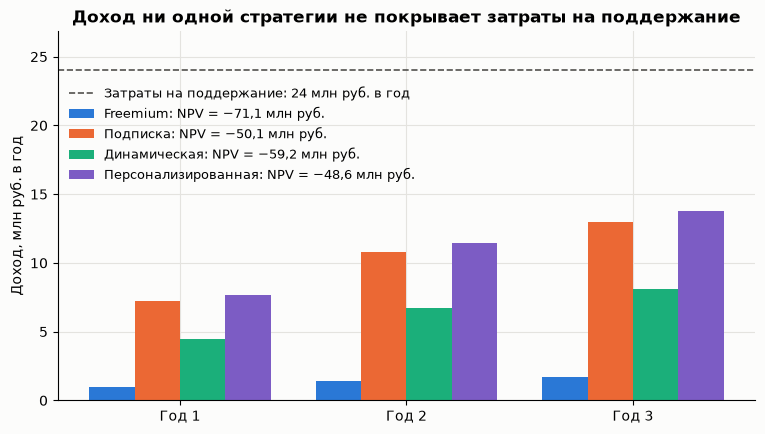

In [16]:
# График 3. Доход по годам для каждой стратегии и затраты на поддержание
year_labels = [f"Год {year}" for year in range(1, YEARS + 1)]
x = np.arange(YEARS)
fig, ax = plt.subplots()
for index, name in enumerate(names):
    values = runs[name]["Доход"].iloc[1:] / MLN
    ax.bar(x + (index - 1.5) * width, values, width, color=COLORS[name],
           label=f"{name}: NPV = {fmt(npv_by_strategy[name] / MLN, 1)} млн руб.")
ax.axhline(BASE["support"] * 12 / MLN, color=GRAY, linewidth=1.2, linestyle="--",
           label=f"Затраты на поддержание: {fmt(BASE['support'] * 12 / MLN)} млн руб. в год")
ax.set_xticks(x, year_labels)
ax.set_ylabel("Доход, млн руб. в год")
ax.set_ylim(0, BASE["support"] * 12 / MLN * 1.12)
ax.set_title("Доход ни одной стратегии не покрывает затраты на поддержание")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.88), fontsize=9)
fig.savefig(os.path.join(FIG_DIR, "03_revenue.png"), dpi=160, bbox_inches="tight")
plt.show()

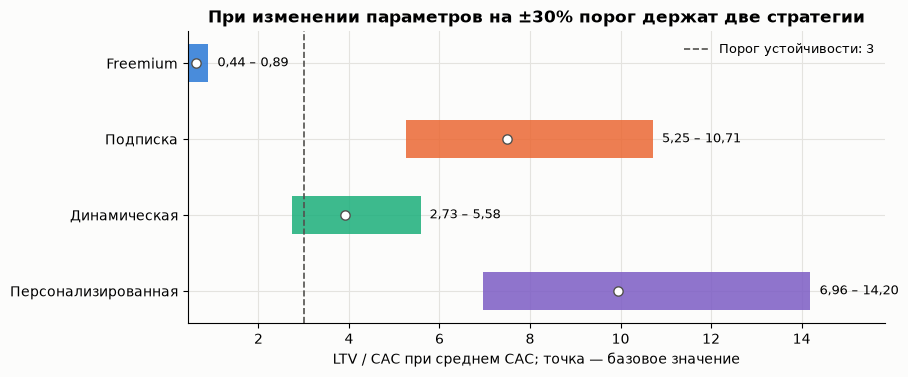

In [17]:
# График 4. Чувствительность: диапазон LTV/CAC при изменении параметров на ±30%
fig, ax = plt.subplots(figsize=(9, 3.8))
for position, name in enumerate(reversed(names)):
    low, high = sens_ratio[name].min(), sens_ratio[name].max()
    ax.barh(position, high - low, left=low, height=0.5, color=COLORS[name], alpha=0.85)
    ax.scatter([sens_ratio[name].iloc[0]], [position], color="white", edgecolor=GRAY,
               s=45, zorder=3)
    ax.text(high + 0.2, position, f"{fmt(low, 2)} – {fmt(high, 2)}", va="center", fontsize=9)
ax.axvline(TARGET_LTV_CAC, color=GRAY, linewidth=1.2, linestyle="--",
           label=f"Порог устойчивости: {TARGET_LTV_CAC}")
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_yticks(range(len(names)), list(reversed(names)))
ax.set_xlabel("LTV / CAC при среднем CAC; точка — базовое значение")
ax.set_title("При изменении параметров на ±30% порог держат две стратегии")
ax.margins(x=0.12)
fig.savefig(os.path.join(FIG_DIR, "03_sensitivity.png"), dpi=160, bbox_inches="tight")
plt.show()

In [18]:
# Сохраняем главные показатели в файл reports/03_summary.json
summary = {
    "price": {name: price_of(s) for name, s in STRATEGIES.items()},
    "arpu": {name: arpu_of(s) for name, s in STRATEGIES.items()},
    "ltv": {name: ltv_of(s) for name, s in STRATEGIES.items()},
    "ltv_cac": {name: {channel: ltv_of(s) / cac for channel, cac in channels.items()}
                for name, s in STRATEGIES.items()},
    "users_by_year": users,
    "profit_by_year": {name: run["Прибыль"].tolist() for name, run in runs.items()},
    "npv": npv_by_strategy,
    "ltv_cac_worst": sens_ratio.min().to_dict(),
    "npv_worst": (sens_npv.min() * MLN).to_dict(),
    "npv_best": (sens_npv.max() * MLN).to_dict(),
    "most_robust": most_robust,
    "choice": CHOICE,
    "users_to_cover_support": users_needed,
}
with open(os.path.join("..", "reports", "03_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("Показатели сохранены в reports/03_summary.json")

Показатели сохранены в reports/03_summary.json


## 3. Анализ результатов

### 3.1. Интерпретация полученных данных

- **ARPU (задание 1).** Больше всего приносит один пользователь при персонализированной стратегии (318 руб. в месяц)
  и при подписке (300 руб.). У динамической стратегии 187,5 руб., у Freemium всего 40 руб.: цена высокая
  (2 000 руб.), но платят только 2% пользователей.
- **LTV (задание 2).** Порядок тот же: персонализированная — 7 950 руб., подписка — 6 000 руб., динамическая —
  3 125 руб., Freemium — 500 руб. На LTV влияет не только ARPU, но и отток: при Churn 4% клиент остается
  в среднем 25 месяцев, при 8% — 12,5 месяца.
- **LTV/CAC (задание 3).** Подписка и персонализированная стратегия проходят порог 3 во всех трех каналах, даже
  в самом дорогом — рекламе (4,0 и 5,3). Динамическая стратегия проходит порог в контент-маркетинге (3,9)
  и виральном росте, но не в рекламе (2,1). Freemium окупает привлечение только при виральном росте (5,0);
  в рекламе LTV/CAC равен 0,33 — пользователь стоит втрое дороже, чем приносит.
- **Прибыль (задание 4).** Все четыре стратегии убыточны в каждом году. Причина одна: база мала. Даже в году 3
  это 3 600 пользователей (0,72% рынка), и лучший доход — 13,74 млн руб. в год при затратах на поддержание
  24 млн руб. в год. Убыток сокращается от года к году только у стратегий с высоким ARPU: у подписки с 17,60
  до 11,52 млн руб.
- **NPV (задание 5).** Персонализированная — −48,62 млн руб., подписка — −50,07, динамическая — −59,17,
  Freemium — −71,10. Из этих сумм 15 млн руб. — затраты на разработку, одинаковые для всех стратегий.

### 3.2. Сравнение с альтернативными вариантами

- **Чувствительность LTV/CAC (задание 6).** LTV/CAC — это произведение и частное параметров, поэтому в процентах
  он меняется одинаково у всех стратегий: конверсия ±30% дает ±30%; рост Churn или CAC на 30% дает −23%, снижение
  на 30% дает +43%. Разница между стратегиями — в запасе до порога 3.
- **Чувствительность NPV (задание 6).** Сильнее всего NPV зависит от конверсии: у подписки от −57,35 до
  −42,80 млн руб. CAC меняет NPV только на ±0,5 млн руб., потому что за 3 года привлекается всего 2 600
  пользователей. Churn на NPV не влияет: по условию база пользователей задана моделью роста (допущение Д4).
  Ни в одном варианте NPV не становится положительным.
- **Устойчивость (задание 7).** В худшем варианте LTV/CAC у персонализированной стратегии равен 6,96, у подписки —
  5,25: обе остаются выше порога 3 при любом изменении. Динамическая при падении конверсии на 30% опускается
  до 2,73 — ниже порога. Freemium ниже порога всегда (от 0,44 до 0,89). Наиболее устойчива персонализированная
  стратегия, на втором месте подписка.
- **Числа и оценки из лекции (задание 8).** По расчету первая — персонализированная стратегия, но ее отрыв от
  подписки мал: 1,46 млн руб. NPV, или 2,9%. При этом ее результат зависит от допущения Д1: она обгоняет
  подписку, только если средняя цена выше 2 500 руб., а в расчете принято 2 650 руб. У подписки все числа взяты
  из условия без допущений о цене. Динамическая стратегия сравнялась бы с подпиской по ARPU только при средней
  цене 2 000 руб., то есть если бы все платили верхнюю границу диапазона.

## 4. Выводы и рекомендации

### 4.1. Ключевые выводы

1. По ARPU, LTV и NPV лидируют две стратегии с близкими результатами: персонализированная (ARPU 318 руб.,
   LTV 7 950 руб., NPV −48,62 млн руб.) и подписка (300 руб., 6 000 руб., −50,07 млн руб.).
2. Порог LTV/CAC ≥ 3 во всех каналах и при изменении параметров на ±30% выдерживают только эти две стратегии.
3. Freemium при заданной конверсии 2% не подходит: LTV 500 руб. окупает привлечение только при виральном росте.
4. При базе 1 000–3 600 пользователей убыточны все стратегии: доход не покрывает затраты на поддержание
   (24 млн руб. в год). Выбор ценовой стратегии уменьшает убыток, но не убирает его — нужен рост базы.
5. **Оптимальная стратегия для вывода на рынок — подписка** (обоснование в разделе 4.2).

### 4.2. Практические рекомендации для «AI-Копирайтер»

**Выбор стратегии (задание 8).** Рекомендуется подписка за 1 500 руб. в месяц с пробным периодом. Причины:

1. По расчету она почти не уступает лидеру: разница в NPV 2,9%, LTV/CAC выше порога во всех каналах.
2. Ее числа надежнее: цена задана в условии одним числом. Результат персонализированной стратегии держится на
   допущении о средней цене.
3. По матрице из лекции (раздел 7.1) у подписки низкая сложность и низкие затраты на внедрение и низкий риск для
   пользователей; она подходит для B2B и сервисов — это и есть аудитория «AI-Копирайтер» (маркетологи,
   SMM-специалисты, предприниматели). У персонализированной стратегии сложность и затраты «очень высокие», риск
   «высокий». Эти затраты в расчет NPV не входят, а они съели бы преимущество в 1,46 млн руб.
4. Вывод лекции (раздел 8.1): подписка — самая устойчивая модель для B2B-сервисов при LTV/CAC > 3. Условие
   выполнено.

**План внедрения (задание 9).**

*Коммуникационная стратегия:*
- главное сообщение — одна понятная цена и пробный период: «попробуйте бесплатно, потом 1 500 руб. в месяц»;
- цена находится в нижней половине диапазона конкурентов (500–5 000 руб.), это стоит показывать в сравнении;
- основные каналы — контент-маркетинг и SEO (LTV/CAC 7,5) и виральный рост (60): примеры сгенерированных текстов,
  кейсы клиентов, приглашения коллег. Реклама (LTV/CAC 4,0) — как дополнение, пока порог 3 выдерживается.

*Дорожная карта:*
- год 1, выход на рынок: запуск подписки с пробным периодом, рост базы с 1 000 до 2 000 пользователей, проверка
  конверсии 20% и Churn 5% на реальных данных;
- год 2, рост: база 3 000 пользователей, перенос бюджета в каналы с лучшим LTV/CAC, работа над удержанием;
- год 3, зрелость: база 3 600 пользователей, ввод нескольких тарифов (многоуровневая подписка из лекции,
  раздел 3.3) как первый шаг к разным ценам для разных сегментов;
- общий ориентир: MRR покрывает затраты на поддержание при базе 6 667 пользователей. Модель роста из условия
  дает 3 600, поэтому нужно либо расти быстрее, либо снижать затраты на поддержание.

*Ключевые метрики для мониторинга* (лекция, разделы 3.4 и 7.2):
- MRR — сейчас 0,60 → 0,90 → 1,08 млн руб. по годам, цель — не ниже 2 млн руб.;
- Churn — 5% в месяц, цель для B2B — ниже 5%;
- LTV/CAC по каналам — 4,0 / 7,5 / 60, цель — не ниже 3;
- окупаемость CAC — 5,0 / 2,7 / 0,3 месяца, цель — быстрее 12 месяцев;
- конверсия из пробного периода — 20%; NRR (удержание выручки) — цель выше 120%, в условии данных для него нет.

**Риски и меры (задание 10).**

| Риск | Что показывает расчет | Мера |
|---|---|---|
| База растет медленно, доход не покрывает поддержание | Убыток во всех годах; нужно 6 667 пользователей, а в году 3 их 3 600 | Вкладывать в дешевые каналы (виральный рост, контент), снижать затраты на облако, искать финансирование на период роста |
| Конверсия из пробного периода ниже 20% | При −30% NPV падает до −57,35 млн руб., LTV/CAC — до 5,25 | Отслеживать конверсию еженедельно, улучшать пробный период, напоминать о его окончании |
| Отток выше 5% | При +30% LTV падает до 4 615 руб., LTV/CAC — до 5,77 | Годовая подписка со скидкой, обучение клиентов, новые функции |
| Рост CAC | При +30% LTV/CAC в рекламе падает с 4,0 до 3,1 — почти до порога | Не наращивать рекламу без проверки LTV/CAC, развивать виральный канал |
| Ценовое давление конкурентов | Конкуренты продают от 500 руб. в месяц | Отличаться качеством текстов, не втягиваться в ценовую войну |
| При переходе к разным ценам для сегментов — ощущение несправедливости | Риск из лекции (разделы 4.3 и 5.3) | Открытые тарифы с понятными отличиями вместо скрытых индивидуальных цен |